<img src="img1/Banner Curso 3_.jpg" width="921" height="89" align="center"/>

<h1><center>Deep Learning - AnáhuacX</center></h1>
<h2><center>Actividad 1: Predicción de XNOR</center></h2>

<p style='text-align: justify;'>El siguiente ejercicio tiene como objetivo que practiques los fundamentos de las redes neuronales, desde la definiciónd de la <strong>tasa de aprendizaje</strong>, hasta la construcción de los parámetros para el <strong>backward propagation</strong>.</p>
    
<p style='text-align: justify;'>Estaremos trabajando con la tabla de verdad de un <strong>X-NOR</strong>, la cual es la negación de la función vista durante la semana. Te proporcionaremos de ciertas partes de código que estarán vacías. Nosotros te guiaremos para que puedas terminar tu ejercicio y de esta manera contestes las preguntas encontradas en tu plataforma de edX.</p>

<p>En seguida te mostramos su tabla de verdad.</p>

| A 	| B 	| C 	| Y 	|
|:--:	|:--:	|:--:	|:-:	|
|  0 	|  0 	|  0 	| 1 	|
|  0 	|  0 	|  1 	| 0 	|
| 0  	| 1  	| 0  	| 0 	|
| 0  	| 1  	| 1  	| 1 	|
| 1  	| 0  	| 0  	| 0 	|
| 1  	| 0  	| 1  	| 1 	|
|  1 	|  1 	|  0 	| 1 	|
| 1  	| 1  	| 1  	| 0 	|

<p style='text-align: justify;'>En la tabla anterior se muestra que en la primera entrada donde todos los bits son cero, la salida es uno pero en la última entrada donde todos los bits son uno, la salida es cero. Cuando tenemos una cantidad par de ceros se asignará una salida de cero y en caso contrario se asigna una salida de uno. La red neuronal que verás a continuación funcionará de manera similar.</p> 

<ol>
    <li>Ejecuta las siguientes celdas, a saber:</li>
    <ol>
        <li>Las librerías que estaremos utilizando durante la libreta.</li>
        <li>Los arreglos de entrada y salida.</li>
    </ol>
</ol>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from numpy.random import seed
seed(30) ## No muevas este parámetro, nos aseguramos de que tus resultados (si haces bien el ejercicio) estén alineados con las opciones de la plataforma de edX.

In [2]:
# Arreglos de entrenamiento.
X = np.array(([0,0,0],
              [0,0,1],
              [0,1,0],
              [0,1,1],
              [1,0,0],
              [1,0,1],
              [1,1,0],
              [1,1,1]), dtype = float)

y = np.array(([1],
              [0],
              [0],
              [1],
              [0],
              [1],
              [1],
              [0]), dtype = float)

<ol start=2>
    <li>Construirás una red neuronal con <strong>una</strong> capa oculta entre la capa de entrada y salida. Configura los siguientes parámetros:</li>
    <ol>
        <li>El valor de la tasa de aprendizaje <em>(lr)</em> con un valor de 0.7.</li>
        <li>Los pesos que van de la capa de entrada a la capa oculta: Toma en cuenta que debes utilizar <strong>seis</strong> neuronas en tu capa oculta. Además, configura los pesos de tal forma que sean "aleatorios".</li>
        <li>Los pesos que van desde la capa oculta hasta la salida.</li>
        <li>Configura una variable de salida con el nombre de <strong>output</strong>.</li>
    </ol>
</ol>
<p>En la libreta te incluimos las variables restantes.</p>

In [3]:
lr = 0.7
w0 = np.random.randn(X.shape[1],6)
w1 = np.random.randn(6, 1)
output = np.zeros(y.shape)
Z0,z1,a0,a1,a2,errors = [],[],[],[],[],[]

<ol start=3>
    <li>Imprime los pesos que van desde la capa de entrada hasta la capa oculta y responde a la siguiente pregunta: <strong>¿Cuál es el peso encontrado en la posición (2, 3)? (Toma en cuenta que en Python comenzamos a contar a partir del 0)</strong></li>
</ol> 

In [5]:

print(w0[2, 3])

0.7603850849562862


<ol start=4>
    <li>Imprime los pesos que van desde la capa oculta hasta la capa de salida y responde a la siguiente pregunta: <strong>¿Cuál es el peso encontrado en la posición (4, 0)? (Toma en cuenta que en Python comenzamos a contar a partir del 0)</strong></li>
</ol> 

In [7]:
print(w1[4, 0])

-0.4230152990413028


<ol start=5>
    <li>Escribe la función sigmoide junto con la función que permite la derivación de la función sigmoide</li>
</ol> 

In [8]:
def sigmoid(t):
    return 1/(1+np.exp(-t))

def sigmoid_derivative(p):
    return sigmoid(p) * sigmoid(1 - p)

<ol start=6>
    <li>Configura la función feedforward. En el cuaderno encontrarás algunas líneas de codigo escritas. Deberás completar los demás elementos.</li>
</ol> 

In [11]:
def feedforward(X_input):
    
    #np.dot regresa el producto punto de dos arreglos.
    global a0,z0,a1,z1,a2
    
    # La activación de la capa cero, es la entrada.
    a0 = X_input
    z0 = np.dot(a0,w0) # NOTA: En esta sección se sumarían los baias si existieran.
    
    # La activación de la capa uno, es la información de las neuronas anteriores (Entradas)  
    # a través de la función de activación "sigmoide".
    a1 = sigmoid(z0)
    z1 = np.dot(a1,w1)
    
    # La activación de la capa dos, es la información de las neuronas anteriores (Capa 1)  
    # a través de la función de activación "sigmoide".
    a2 = sigmoid(z1)
    
    # En esta red, aquí terminamos, porque no hay más capas.
    output = a2
    
    return output

<ol start=7>
    <li>Configura la función backprop. En el cuaderno encontrarás algunas líneas de codigo escritas. Deberás completar los demás elementos.</li>
</ol> 

In [ ]:
def backprop():
    # Aplicando la regla de la cadena para la función de perdida respecto a los pesos 2 y 1.
    # .T devuelve la matriz traspuesta
    global w0,w1,b0,b1,b2
    
    # Calcular el error MSE --> Mean Square Error.
    mse = np.sum( (1 / 2) * (y - output) * (y - output))
    errors.append(mse)

    delta1 = -(y - output) * sigmoid_derivative(z1)
    d_w1 = np.dot(a1.T,delta1)
    d_b1 = delta1
    
    delta0 = np.dot(delta1,w1.T) * sigmoid_derivative(z0)
    d_w0 = np.dot(a0.T,delta0)
    d_b0 = delta0

    # lr --> Learning Rate, es un parametro propuesto por el investigador
    # que indica que tanta importancia le asignamos a los errores del pasado.
    w1 = w1 - lr * d_w1
    w0 = w0 - lr * d_w0

<ol start=8>
    <li>Entrena tu red neuronal con 2000 repeticiones. Tendrás que configurar el ciclo for para que las iteraciones se hagan correctamente. Algunas líneas de código las dejamos para ti. Revisa lo aboradado durante la semana para completar esta parte.</li>
</ol> 

In [13]:
# Sesión de entrenamiento
repeticiones = 2000

for i in range(repeticiones):
   
    # Primero se realiza el feedforward y despues el back propagation
    output = feedforward(X)
    backprop()
    # Las siguientes líneas muestran el error cada 10 sesiones.
    if i % 10 == 0:
        print("Epoch: {}, mse: {}".format(i,errors[-1]))

Epoch: 0, mse: 1.107185457169858
Epoch: 10, mse: 1.0240230211161379
Epoch: 20, mse: 1.0131726770173235
Epoch: 30, mse: 1.0060087082593743
Epoch: 40, mse: 1.0005169763690263
Epoch: 50, mse: 0.9959347009775865
Epoch: 60, mse: 0.9915883466409066
Epoch: 70, mse: 0.9866750576896511
Epoch: 80, mse: 0.9801545171209364
Epoch: 90, mse: 0.9706033039547192
Epoch: 100, mse: 0.9561001933518043
Epoch: 110, mse: 0.9343122482519097
Epoch: 120, mse: 0.9028656272987788
Epoch: 130, mse: 0.8597114823395664
Epoch: 140, mse: 0.803083400872497
Epoch: 150, mse: 0.7315732463898912
Epoch: 160, mse: 0.6458307551476887
Epoch: 170, mse: 0.5514913382598263
Epoch: 180, mse: 0.45895299658778377
Epoch: 190, mse: 0.377818765173201
Epoch: 200, mse: 0.31192427305244075
Epoch: 210, mse: 0.26019268885133556
Epoch: 220, mse: 0.21982759441919128
Epoch: 230, mse: 0.18813812380485662
Epoch: 240, mse: 0.16301224060003933
Epoch: 250, mse: 0.142869757917035
Epoch: 260, mse: 0.1265254220214358
Epoch: 270, mse: 0.11308527150836167


<ol start=9>
    <li>Imprime los nuevos pesos configurados por el entrenamiento entre la capa de entrada y la oculta y contesta la siguiente pregunta: <strong>¿Cuál es el peso encontrado en el lugar (2, 3)?</strong></li>
</ol> 

In [15]:
w0
print(w0[2, 3])

5.142063097140725


<ol start=9>
    <li>Imprime los nuevos pesos configurados por el entrenamiento entre la capa oculta y la de salida y contesta la siguiente pregunta: <strong>¿Cuál es el peso encontrado en el lugar (4, 0)?</strong></li>
</ol> 

In [17]:
w1
print(w1[4, 0])

-5.115881476524916


<ol start=10>
    <li>Utiliza tu red neuronal y predice el resultado aplicando la siguiente entrada de números a la red:</li>
</ol> 
Entrada propuesta $x = [1,0,1]$
<br>Salida esperada $y=1$ (Debido a que tiene un número impar de ceros).

In [18]:
output = feedforward([1,0,1])
output

array([0.98862138])

<ol start=11>
    <li><strong>¿Cuál es el resultado de la predicción?</strong></li>
</ol> 

Recuerda que esto es una predicción, y, si nuestra red está funcionando bien, nos habrá dado como resultado un número muy cercano al 1 o muy cercano al 0 dependiendo de nuestras entradas.

El resultado fue 0.98862138

<ol start=12>
    <li>Ahora, usa tu red neuronal y predice el resultado con esta otra entrada de números:</li>
</ol> 
Entrada propuesta $x = [0,0,1]$
<br>Salida esperada $y=0$ (Debido a que tiene un número par de ceros).

In [19]:
output = feedforward([0,0,1])
output

array([0.03359343])

<ol start=13>
    <li><strong>¿Cuál fue el resultado de la predicción?</strong></li>
</ol> 

El resultado fue 0.033559343

<ol start=14>
    <li>Grafica el comportamiento de los errores durante la predicción.</li>
</ol> 

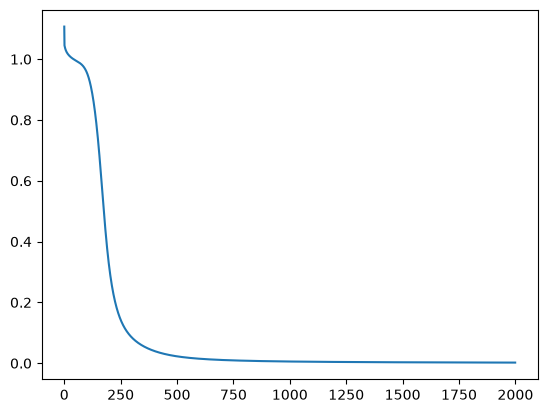

In [20]:
plt.plot(errors)

<img src="img1/Anáhuac_edX.png" width="498" height="150" align="center"/>